# Product Clustering — Approach 1: Mixed Vector + Spark K-Means

**Feature:** `mixed_vector` (semantic embeddings + numerical attributes, Task 2 pipeline)
**Algorithm:** Apache Spark MLlib Distributed K-Means
**Scale:** Full 5,737,625 products — streamed in batches from ClickHouse

| Parameter | Value |
|---|---|
| Feature vector | `mixed_vector` (387-dim) |
| PCA dims | 387 → 50 |
| Batch size | 20,000 products |
| Random seed | 42 |
| k (clusters) | Set after elbow analysis |


## 1. Environment Setup

Windows Hadoop/Spark configuration via winutils.exe. Skipped on macOS/Linux.


In [1]:
import os, sys

if sys.platform == 'win32':
    import urllib.request, pathlib
    os.environ['HADOOP_HOME'] = str(pathlib.Path.home() / 'hadoop')
    winutils_path = pathlib.Path(os.environ['HADOOP_HOME']) / 'bin' / 'winutils.exe'
    if not winutils_path.exists():
        winutils_path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(
            'https://github.com/cdarlint/winutils/raw/master/hadoop-3.3.5/bin/winutils.exe',
            str(winutils_path)
        )
        print('winutils.exe downloaded.')
    else:
        print('winutils.exe already present.')
    os.environ['HADOOP_HOME'] = str(pathlib.Path.home() / 'hadoop')
    os.environ['PATH'] = os.environ['PATH'] + ';' + os.environ['HADOOP_HOME'] + '/bin'
else:
    print('macOS/Linux — skipping winutils setup.')


winutils.exe already present.


## 2. Imports & Configuration

In [ ]:
import sys, os, ast, time
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import euclidean_distances

from pyspark.sql import SparkSession
from pyspark.ml.clustering import KMeans as SparkKMeans
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.sql.functions import udf, col
from pyspark.sql.types import ArrayType, FloatType

from common.const import SCHEMA
from common.helper import clickhouse_extract_data_as_df

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

#  Configuration 
PCA_SAMPLE_SIZE = 50_000   # products for PCA fitting
PCA_COMPONENTS  = 50       # target PCA dimensions
BATCH_SIZE      = 10_000   # products per ClickHouse batch
RANDOM_SEED     = 42

# Elbow analysis
K_RANGE      = range(2, 17)
ELBOW_SAMPLE = 20_000
SILHOUETTE_N = 5_000

print('Imports OK')
print(f'Feature      : mixed_vector (387-dim)')
print(f'PCA sample   : {PCA_SAMPLE_SIZE:,} → {PCA_COMPONENTS} dims')
print(f'Batch size   : {BATCH_SIZE:,}')


Imports OK
Feature      : mixed_vector (387-dim)
PCA sample   : 50,000 → 50 dims
Batch size   : 10,000


## 3. Phase 1a — Sample for PCA Fitting

In [ ]:
#  Sample 50,000 products for PCA fitting 
print(f'Fetching ~{PCA_SAMPLE_SIZE:,} products for PCA fitting')
start = time.time()

sample_query = f"""
SELECT parent_asin, mixed_vector
FROM {SCHEMA}.featured_dense_vectors
WHERE length(mixed_vector) > 0
  AND rowNumberInAllBlocks() % 114 = 0
LIMIT {PCA_SAMPLE_SIZE}
"""

sample_df = clickhouse_extract_data_as_df(sample_query)
sample_df.columns = [str(c).strip() for c in sample_df.columns]
print(f'Fetched   : {len(sample_df):,} rows in {time.time()-start:.1f}s')
print(f'Columns   : {list(sample_df.columns)}')
print(sample_df.head(3))


Fetching ~50,000 products for PCA fitting...
Fetched   : 50,000 rows in 12.1s
Columns   : ['parent_asin', 'mixed_vector']
  parent_asin                                       mixed_vector
0  B00HXT83SM  [-0.008968086, 0.011292071, -0.005977449, -0.0...
1  B00HY4FHL2  [-0.008560705, -0.008223788, 0.023301013, 0.00...
2  B00HYHVAK6  [-0.038814906, 0.040133584, 0.0062720664, 0.01...


### 3b. Parse Sample Vectors

In [ ]:
def parse_vector(v):
    try:
        if isinstance(v, list):
            return np.array(v, dtype=np.float32)
        if isinstance(v, str):
            return np.array(ast.literal_eval(v), dtype=np.float32)
    except Exception:
        return None

sample_df['parsed'] = sample_df['mixed_vector'].apply(parse_vector)
sample_df = sample_df[sample_df['parsed'].notna()].reset_index(drop=True)

X_sample = np.vstack(sample_df['parsed'].values).astype(np.float32)
# L2 normalise
X_sample = normalize(X_sample, norm='l2')

print(f'PCA sample matrix shape : {X_sample.shape}')
print(f'dtype                   : {X_sample.dtype}')
print(f'RAM estimate            : {X_sample.nbytes / 1e6:.1f} MB')


PCA sample matrix shape : (50000, 387)
dtype                   : float32
RAM estimate            : 77.4 MB


## 4. Phase 1b — Fit PCA

PCA reduces 387-dim `mixed_vector` to 50 dense dims. Applied batch-by-batch in Phase 2.

In [ ]:
print(f'Fitting PCA: {X_sample.shape[1]} to {PCA_COMPONENTS} dims on {len(X_sample):,} samples')
start = time.time()

pca = PCA(n_components=PCA_COMPONENTS, random_state=RANDOM_SEED)
X_sample_reduced = pca.fit_transform(X_sample)

print(f'PCA fitted in     : {time.time()-start:.1f}s')
print(f'Reduced shape     : {X_sample_reduced.shape}')
print(f'Variance explained: {pca.explained_variance_ratio_.sum():.2%}')
print(f'Top 10 component var: {pca.explained_variance_ratio_[:10].round(4)}')
print()
print('PCA is ready.')


Fitting PCA: 387 → 50 dims on 50,000 samples...
PCA fitted in     : 0.1s
Reduced shape     : (50000, 50)
Variance explained: 68.06%
Top 10 component var: [0.0963 0.0822 0.0547 0.038  0.0322 0.0278 0.021  0.0207 0.017  0.0163]

PCA is ready.


## 5. Optimal k — Elbow + Silhouette

k tested from 2–16 on 20,000 PCA-reduced products.

In [ ]:
# Independent RNG 
rng  = np.random.default_rng(42)
rng2 = np.random.default_rng(43)

n_elbow    = min(ELBOW_SAMPLE, len(X_sample_reduced))
s_idx      = rng.choice(len(X_sample_reduced), n_elbow, replace=False)
sample_emb = X_sample_reduced[s_idx]

sil_n   = min(SILHOUETTE_N, n_elbow)
sil_idx = rng2.choice(n_elbow, sil_n, replace=False)

k_values, wcss_values, sil_values = [], [], []
print(f'Testing k ∈ {{2..16}} on {n_elbow:,} PCA-reduced products')
print()

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10, max_iter=300)
    labels = km.fit_predict(sample_emb)
    wcss   = km.inertia_
    sil    = silhouette_score(sample_emb[sil_idx], labels[sil_idx], metric='cosine')
    k_values.append(k); wcss_values.append(wcss); sil_values.append(sil)
    print(f'  k={k:2d} : WCSS={wcss:>10.2f}  Silhouette={sil:.4f}')


Testing k ∈ {2..16} on 20,000 PCA-reduced products

  k= 2 : WCSS=   1382.14  Silhouette=0.2161
  k= 3 : WCSS=   1254.44  Silhouette=0.1713
  k= 4 : WCSS=   1173.64  Silhouette=0.1999
  k= 5 : WCSS=   1106.64  Silhouette=0.1829
  k= 6 : WCSS=   1060.58  Silhouette=0.1801
  k= 7 : WCSS=   1016.84  Silhouette=0.1738
  k= 8 : WCSS=    993.38  Silhouette=0.1706
  k= 9 : WCSS=    973.92  Silhouette=0.1600
  k=10 : WCSS=    956.38  Silhouette=0.1564
  k=11 : WCSS=    938.99  Silhouette=0.1463
  k=12 : WCSS=    924.32  Silhouette=0.1568
  k=13 : WCSS=    906.99  Silhouette=0.1427
  k=14 : WCSS=    891.63  Silhouette=0.1502
  k=15 : WCSS=    885.55  Silhouette=0.1539
  k=16 : WCSS=    870.24  Silhouette=0.1583

Review the plot in the next cell then set N_CLUSTERS manually.


### 5b. Elbow & Silhouette Plot

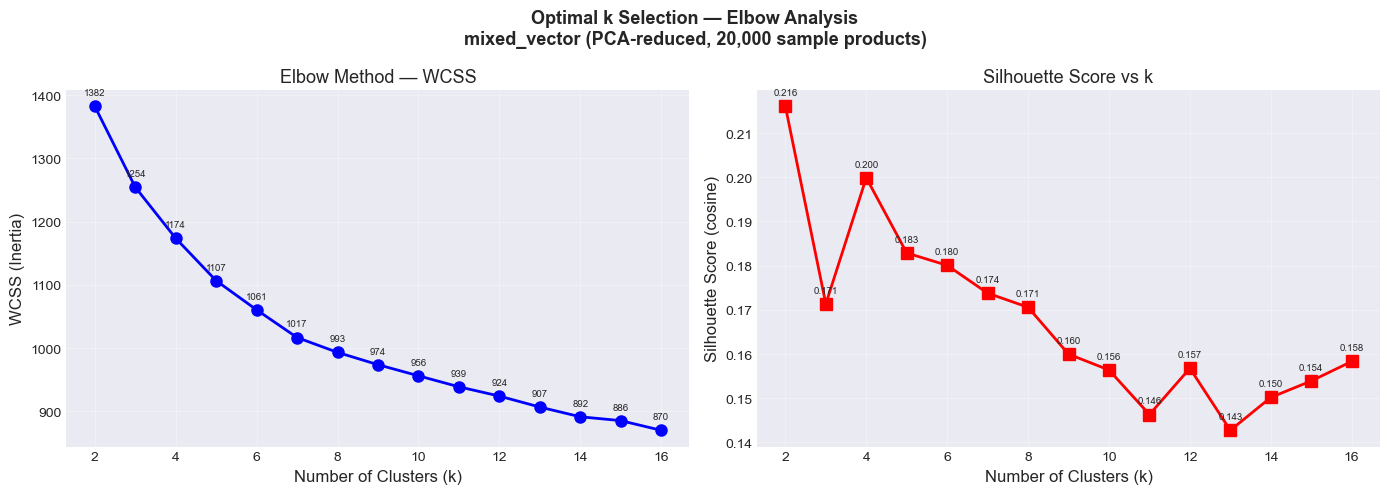

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'Optimal k Selection — Elbow Analysis\n'
    f'mixed_vector (PCA-reduced, {n_elbow:,} sample products)',
    fontsize=13, fontweight='bold'
)

axes[0].plot(k_values, wcss_values, 'bo-', lw=2, ms=8)
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[0].set_ylabel('WCSS (Inertia)', fontsize=12)
axes[0].set_title('Elbow Method — WCSS', fontsize=13)
axes[0].grid(alpha=0.3)
for x, y in zip(k_values, wcss_values):
    axes[0].annotate(f'{y:.0f}', (x, y), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=7)

axes[1].plot(k_values, sil_values, 'rs-', lw=2, ms=8)
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12)
axes[1].set_ylabel('Silhouette Score (cosine)', fontsize=12)
axes[1].set_title('Silhouette Score vs k', fontsize=13)
axes[1].grid(alpha=0.3)
for x, y in zip(k_values, sil_values):
    axes[1].annotate(f'{y:.3f}', (x, y), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=7)
plt.savefig('elbow_mixed_kmeans.png', dpi=150, bbox_inches='tight')
plt.tight_layout()
plt.show()




### 5c. k Selection

After k==2 ,k=4 is the local silhouette peak  but for  5.7M products,  considered too small , k=8 clusters gives more meaningful business segments(Silhouette 0.171 and WCSS still declining but slowing).


In [8]:
N_CLUSTERS = 8   
print(f'N_CLUSTERS = {N_CLUSTERS}')

N_CLUSTERS = 8


## 6. Start Spark Session

In [9]:
spark = SparkSession.builder \
    .appName('Task3A_ProductClustering_SparkKMeans_MixedVector') \
    .config('spark.driver.memory', '8g') \
    .config('spark.executor.memory', '8g') \
    .config('spark.sql.shuffle.partitions', '200') \
    .config('spark.default.parallelism', '4') \
    .getOrCreate()

spark.sparkContext.setLogLevel('WARN')
print(f'Spark version : {spark.version}')
print('Spark session started.')


Spark version : 3.5.0
Spark session started.


## 7. Phase 2 — Stream Full Dataset into Spark

Fetch all 5.7M products in batches of 50,000 using `LIMIT/OFFSET`.
PCA-transform each batch, accumulate into list, then load into Spark.

In [10]:
# Count total products 
count_query = f"""
SELECT count(*) as n
FROM {SCHEMA}.featured_dense_vectors
WHERE length(mixed_vector) > 0
"""
count_df   = clickhouse_extract_data_as_df(count_query)
TOTAL_ROWS = int(count_df.iloc[0, 0])
n_batches  = int(np.ceil(TOTAL_ROWS / BATCH_SIZE))

print(f'Total products  : {TOTAL_ROWS:,}')
print(f'Batch size      : {BATCH_SIZE:,}')
print(f'Total batches   : {n_batches}')


Total products  : 5,737,625
Batch size      : 10,000
Total batches   : 574


In [ ]:
# Stream all batches, PCA-transform, accumulate 
all_asins   = []
all_reduced = []

print(f'Streaming {n_batches} batches')
print()
start  = time.time()
failed = 0

for batch_idx in range(n_batches):
    offset = batch_idx * BATCH_SIZE

    batch_query = f"""
    SELECT parent_asin, mixed_vector
    FROM {SCHEMA}.featured_dense_vectors
    WHERE length(mixed_vector) > 0
    LIMIT {BATCH_SIZE} OFFSET {offset}
    """

    # Retry up to 3 times
    batch_df = None
    for attempt in range(3):
        try:
            batch_df = clickhouse_extract_data_as_df(batch_query)
            break
        except Exception as e:
            if attempt == 2:
                failed += 1
                print(f'  WARNING: batch {batch_idx} failed after 3 attempts — {e}')
                batch_df = None
            else:
                print(f'  Retrying batch {batch_idx} (attempt {attempt+2})...')
                time.sleep(5)  # wait 5s before retry

    if batch_df is None:
        continue

    if len(batch_df) == 0:
        break

    batch_df.columns   = [str(c).strip() for c in batch_df.columns]
    batch_df['parsed'] = batch_df['mixed_vector'].apply(parse_vector)
    batch_df = batch_df[batch_df['parsed'].notna()].reset_index(drop=True)

    if len(batch_df) == 0:
        continue

    X_batch = normalize(
        np.vstack(batch_df['parsed'].values).astype(np.float32),
        norm='l2'
    )
    X_reduced = pca.transform(X_batch)

    all_asins.extend(batch_df['parent_asin'].tolist())
    all_reduced.append(X_reduced)

    # Small sleep every batch to avoid error in ClickHouse
    time.sleep(0.5)

    if batch_idx % 20 == 0 or batch_idx == n_batches - 1:
        elapsed = time.time() - start
        pct     = (batch_idx + 1) / n_batches * 100
        eta     = (elapsed / (batch_idx + 1)) * (n_batches - batch_idx - 1)
        print(f'  Batch {batch_idx+1:4d}/{n_batches} ({pct:5.1f}%) | '
              f'Elapsed: {elapsed/60:.1f}m | '
              f'ETA: {eta/60:.1f}m | '
              f'Loaded: {len(all_asins):,} | '
              f'Failed: {failed}')

X_all = np.vstack(all_reduced).astype(np.float32)
print(f'\nStreaming complete in {(time.time()-start)/60:.1f} minutes')
print(f'Total products loaded : {len(all_asins):,}')
print(f'Matrix shape          : {X_all.shape}')
print(f'Failed batches        : {failed}')

Streaming 574 batches

  Batch    1/574 (  0.2%) | Elapsed: 0.0m | ETA: 21.9m | Loaded: 10,000 | Failed: 0
  Batch   21/574 (  3.7%) | Elapsed: 0.8m | ETA: 21.3m | Loaded: 210,000 | Failed: 0
  Batch   41/574 (  7.1%) | Elapsed: 1.6m | ETA: 20.5m | Loaded: 410,000 | Failed: 0
  Batch   61/574 ( 10.6%) | Elapsed: 2.4m | ETA: 20.3m | Loaded: 610,000 | Failed: 0
  Batch   81/574 ( 14.1%) | Elapsed: 3.3m | ETA: 20.1m | Loaded: 810,000 | Failed: 0
  Batch  101/574 ( 17.6%) | Elapsed: 4.2m | ETA: 19.8m | Loaded: 1,010,000 | Failed: 0
  Batch  121/574 ( 21.1%) | Elapsed: 5.2m | ETA: 19.5m | Loaded: 1,210,000 | Failed: 0
  Batch  141/574 ( 24.6%) | Elapsed: 6.3m | ETA: 19.2m | Loaded: 1,410,000 | Failed: 0
  Batch  161/574 ( 28.0%) | Elapsed: 7.4m | ETA: 18.9m | Loaded: 1,610,000 | Failed: 0
  Batch  181/574 ( 31.5%) | Elapsed: 8.6m | ETA: 18.7m | Loaded: 1,810,000 | Failed: 0
  Batch  201/574 ( 35.0%) | Elapsed: 10.0m | ETA: 18.5m | Loaded: 2,010,000 | Failed: 0
  Batch  221/574 ( 38.5%) | El

## 8. Load into Spark & Run K-Means

Convert PCA-reduced numpy matrix to Spark DataFrame then run distributed K-Means.


In [ ]:
# Build Spark DataFrame from PCA-reduced matrix
feature_cols = [f'f_{i}' for i in range(PCA_COMPONENTS)]
embeddings_df = pd.DataFrame(X_all, columns=feature_cols)
embeddings_df['parent_asin'] = all_asins

# Save to parquet for Spark to read efficiently
parquet_path = 'product_embeddings_mixed_pca.parquet'
embeddings_df.to_parquet(parquet_path, index=False, compression='none')
print(f'Saved PCA embeddings to {parquet_path}')

# Load into Spark
spark_df  = spark.read.parquet(parquet_path)
assembler = VectorAssembler(inputCols=feature_cols, outputCol='features_vec')
spark_df  = assembler.transform(spark_df).select('parent_asin', 'features_vec')
print(f'Spark DataFrame ready : {spark_df.count():,} rows')


Saved PCA embeddings to product_embeddings_mixed_pca.parquet
Spark DataFrame ready : 5,737,625 rows


In [ ]:
#  Train Spark K-Means 
print(f'Training Spark K-Means with k={N_CLUSTERS}')
start = time.time()

kmeans = SparkKMeans(
    k=N_CLUSTERS,
    seed=RANDOM_SEED,
    maxIter=20,
    initMode='k-means||',
    featuresCol='features_vec',
    predictionCol='cluster'
)

model   = kmeans.fit(spark_df)
elapsed = time.time() - start

print(f'Training complete in {elapsed:.1f}s')
print(f'WSSSE (Training Cost) : {model.summary.trainingCost:.4f}')


Training Spark K-Means with k=8...
Training complete in 34.1s
WSSSE (Training Cost) : 283969.4672


## 9. Evaluation : Silhouette & WSSSE

Silhouette computed by Spark ClusteringEvaluator using cosine distance.Cosine distance is used because vectors are L2-normalised ,magnitude is removed. Only direction is matter

In [15]:
predictions = model.transform(spark_df)

evaluator = ClusteringEvaluator(
    featuresCol='features_vec',
    predictionCol='cluster',
    metricName='silhouette',
    distanceMeasure='cosine'
)
silhouette = evaluator.evaluate(predictions)
wssse      = model.summary.trainingCost

print('─' * 50)
print('EVALUATION RESULTS')
print('─' * 50)
print(f'Silhouette Score (cosine) : {silhouette:.4f}')
print(f'WSSSE (Training Cost)     : {wssse:.4f}')
print(f'k                         : {N_CLUSTERS}')
print(f'Total products            : {len(all_asins):,}')
print('─' * 50)

print('\nCluster size distribution:')
predictions.groupBy('cluster').count().orderBy('cluster').show()


──────────────────────────────────────────────────
EVALUATION RESULTS
──────────────────────────────────────────────────
Silhouette Score (cosine) : 0.1766
WSSSE (Training Cost)     : 283969.4672
k                         : 8
Total products            : 5,737,625
──────────────────────────────────────────────────

Cluster size distribution:
+-------+-------+
|cluster|  count|
+-------+-------+
|      0| 432643|
|      1|1585985|
|      2| 117603|
|      3| 963115|
|      4|1049114|
|      5|1408461|
|      6| 132474|
|      7|  48230|
+-------+-------+



## 10. Collect Results & Build DataFrame

Collect Spark predictions to driver, merge with metadata.


In [16]:
#  Collect cluster labels from Spark 
results_spark = predictions.select('parent_asin', 'cluster').toPandas()
results_spark.columns = ['parent_asin', 'kmeans_cluster']
print(f'Collected {len(results_spark):,} cluster assignments from Spark')

#  Load metadata in batches 
print('Loading metadata...')
PROFILE_SAMPLE = 3_000
sampled_rows   = []

for cid in range(N_CLUSTERS):
    cluster_asins = results_spark[results_spark['kmeans_cluster'] == cid]['parent_asin'].tolist()
    sample_asins  = cluster_asins[:PROFILE_SAMPLE] if len(cluster_asins) > PROFILE_SAMPLE else cluster_asins
    asin_sql      = "','".join(sample_asins)

    meta_query = f"""
    SELECT parent_asin, title, main_category, product_category,
           CAST(price AS Nullable(Float64)) AS price,
           average_rating, rating_number
    FROM {SCHEMA}.raw_products
    WHERE parent_asin IN ('{asin_sql}')
    """
    meta_df = clickhouse_extract_data_as_df(meta_query)
    meta_df['kmeans_cluster'] = cid
    sampled_rows.append(meta_df)

products_df = pd.concat(sampled_rows, ignore_index=True)
results_df  = results_spark.copy()

print(f'Profile sample : {len(products_df):,} products')
print(f'Full results   : {len(results_df):,} products')
print(f'Main categories: {products_df["main_category"].nunique()}')


Collected 5,737,625 cluster assignments from Spark
Loading metadata...
Profile sample : 22,790 products
Full results   : 5,737,625 products
Main categories: 39


## 11. Cluster Profiling

For each cluster: size, top categories, avg price, avg rating, sample titles.


In [17]:
print('=' * 65)
print('CLUSTER PROFILES — mixed_vector + Spark K-Means (full 5.7M)')
print('=' * 65)

full_sizes = results_df['kmeans_cluster'].value_counts().sort_index()

for cluster_id in sorted(products_df['kmeans_cluster'].unique()):
    cluster_data = products_df[products_df['kmeans_cluster'] == cluster_id]
    full_n       = full_sizes.get(cluster_id, 0)
    full_pct     = full_n / len(results_df) * 100

    top_cats  = cluster_data['main_category'].value_counts().head(3).to_dict()
    avg_price = cluster_data['price'].mean()
    med_price = cluster_data['price'].median()
    avg_rating= cluster_data['average_rating'].mean()
    avg_reviews=cluster_data['rating_number'].mean()

    print(f'\nCluster {cluster_id}')
    print(f'  Full dataset  : {full_n:,} products ({full_pct:.1f}%)')
    print(f'  Profile sample: {len(cluster_data):,} products')
    print(f'  Top categories: {top_cats}')
    print(f'  Avg price     : ${avg_price:.2f}  Median: ${med_price:.2f}')
    print(f'  Avg rating    : {avg_rating:.2f} / 5.0')
    print(f'  Avg reviews   : {avg_reviews:.0f}')
    print(f'  Sample titles :')
    for title in cluster_data['title'].dropna().head(3):
        print(f'    - {str(title)[:80]}')


CLUSTER PROFILES — mixed_vector + Spark K-Means (full 5.7M)

Cluster 0
  Full dataset  : 432,643 products (7.5%)
  Profile sample: 2,991 products
  Top categories: {'Musical Instruments': 835, 'All Electronics': 627, 'Home Audio & Theater': 536}
  Avg price     : $39.97  Median: $24.48
  Avg rating    : 4.06 / 5.0
  Avg reviews   : 80
  Sample titles :
    - The Listening Cards
    - Night Novel Guide Challenge Game
    - Workout Headphones by Arena Essentials

Cluster 1
  Full dataset  : 1,585,985 products (27.6%)
  Profile sample: 3,000 products
  Top categories: {'Arts, Crafts & Sewing': 653, 'Books': 513, 'Industrial & Scientific': 369}
  Avg price     : $21.26  Median: $14.90
  Avg rating    : 4.43 / 5.0
  Avg reviews   : 71
  Sample titles :
    - Patanjali Moisturizer Cream - Pack of 2
    - Yardley Lace Satin Deodorant Spray for women 150 ml (Pack of 2)
    - WOW Organics Apple Cider Vinegar Shampoo - 300 mL

Cluster 2
  Full dataset  : 117,603 products (2.0%)
  Profile sample:

### 11b. Assign Descriptive Cluster Names,after review above cell

In [ ]:

cluster_names = {
    0: 'Audio, Electronics & Instruments',       # Musical Instruments, Electronics, Home Audio
    1: 'Arts, Books & Personal Care',             # Arts & Crafts, Books, Beauty/Shampoo
    2: 'Premium & High-Value Products',           # Avg price — globes, cameras, computers
    3: 'Toys, Games & Collectibles',              # Toys & Games , sports cards, Star Wars
    4: 'Computer & Sewing Accessories',           # Computers, Electronics, Singer foot controllers
    5: 'Phone Cases & Mobile Accessories',        # Cell Phones , iPhone cases, covers
    6: 'Low-Rated & Discontinued Products',       # Avg rating  — very suspicious cluster
    7: 'Popular Craft & Hobby Kits',              # High reviews (, Klutz, Harry Potter
}


products_df['kmeans_cluster_name'] = products_df['kmeans_cluster'].map(cluster_names)
results_df['kmeans_cluster_name']  = results_df['kmeans_cluster'].map(cluster_names)

print('Cluster names assigned.')
print('\nProfile sample distribution:')
print(products_df['kmeans_cluster_name'].value_counts())
print('\nFull dataset distribution:')
print(results_df['kmeans_cluster_name'].value_counts())


Cluster names assigned.

Profile sample distribution:
kmeans_cluster_name
Arts, Books & Personal Care          3000
Toys, Games & Collectibles           3000
Audio, Electronics & Instruments     2991
Phone Cases & Mobile Accessories     2989
Computer & Sewing Accessories        2986
Low-Rated & Discontinued Products    2821
Premium & High-Value Products        2649
Popular Craft & Hobby Kits           2354
Name: count, dtype: int64

Full dataset distribution:
kmeans_cluster_name
Arts, Books & Personal Care          1585985
Phone Cases & Mobile Accessories     1408461
Computer & Sewing Accessories        1049114
Toys, Games & Collectibles            963115
Audio, Electronics & Instruments      432643
Low-Rated & Discontinued Products     132474
Premium & High-Value Products         117603
Popular Craft & Hobby Kits             48230
Name: count, dtype: int64


## 12. Representative Products

3 products closest to each K-Means centroid in 50-dim PCA space.


In [ ]:
print('=' * 65)
print('REPRESENTATIVE PRODUCTS (closest to K-Means centroid)')
print('=' * 65)

centroids = model.clusterCenters()

for cluster_id in range(N_CLUSTERS):
    cluster_data = products_df[products_df['kmeans_cluster'] == cluster_id].copy()
    full_n       = full_sizes.get(cluster_id, 0)
    name         = cluster_names.get(cluster_id, f'Cluster {cluster_id}')

    # PCA vectors for this cluster's sample
    cluster_asins = cluster_data['parent_asin'].tolist()
    asin_to_idx   = {a: i for i, a in enumerate(all_asins)}
    idxs          = [asin_to_idx[a] for a in cluster_asins if a in asin_to_idx]

    if not idxs:
        continue

    vecs     = X_all[idxs]
    centroid = np.array(centroids[cluster_id])
    dists    = np.linalg.norm(vecs - centroid, axis=1)
    top3     = np.argsort(dists)[:3]

    print(f'\n{name}  (full dataset: {full_n:,} products)')
    print(f'  Closest to centroid:')
    for rank, idx in enumerate(top3, 1):
        row   = cluster_data.iloc[idxs.index(idxs[idx]) if idx < len(idxs) else 0]
        title = str(row.get('title', 'N/A'))[:80]
        cat   = str(row.get('main_category', 'N/A'))
        price = row.get('price', None)
        rating= row.get('average_rating', None)
        price_str  = f'${price:.2f}' if pd.notna(price) else 'N/A'
        rating_str = f'{rating:.1f}*' if pd.notna(rating) else 'N/A'
        print(f'  {rank}. [{cat}] {title}')
        print(f'     Price: {price_str}  Rating: {rating_str}')


REPRESENTATIVE PRODUCTS (closest to K-Means centroid)

Audio, Electronics & Instruments  (full dataset: 432,643 products)
  Closest to centroid:
  1. [Musical Instruments] Sennheiser EW-112P G3 (B-Band) Lavalier System w/ Case, Headphones, Headset
     Price: N/A  Rating: 5.0*
  2. [Musical Instruments] Seetronic SP3X-B 1/4-Inch TRS Stereo Phone Plug, Black
     Price: N/A  Rating: 5.0*
  3. [Home Audio & Theater] AKG K501 Hi Fi Headphones
     Price: N/A  Rating: 5.0*

Arts, Books & Personal Care  (full dataset: 1,585,985 products)
  Closest to centroid:
  1. [Arts, Crafts & Sewing] Coastal Chic Batiks Strips 40 2.5-inch Strips Jelly Roll Maywood Studio, Assorte
     Price: N/A  Rating: 5.0*
  2. [Arts, Crafts & Sewing] Drinco Vacuum Insulated Stainless Steel Water Bottle + Stainless Steel Insulated
     Price: N/A  Rating: 5.0*
  3. [Office Products] Dots and Floral Medium Gift Bag
     Price: N/A  Rating: 5.0*

Premium & High-Value Products  (full dataset: 117,603 products)
  Closes

## 13. Visualisations

**Plot 1** — Cluster size bar chart (full 5.7M counts)
**Plot 2** — Category composition heatmap per cluster
**Plot 3** — PCA 2D scatter (sample)


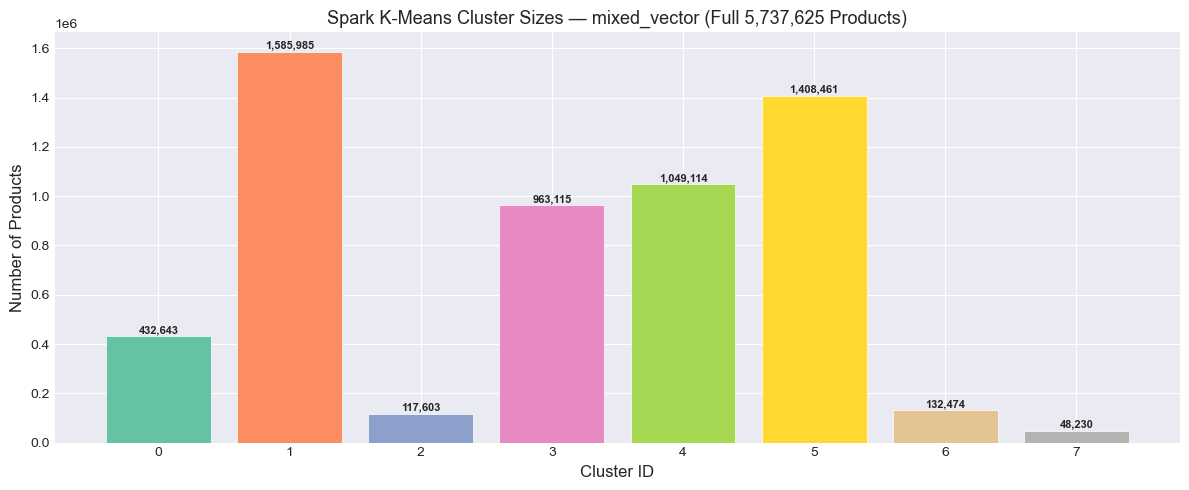

<Figure size 640x480 with 0 Axes>

In [21]:
# Plot 1 — Cluster size bar chart
fig, ax = plt.subplots(figsize=(12, 5))
colors  = cm.Set2(np.linspace(0, 1, N_CLUSTERS))
bars    = ax.bar(full_sizes.index, full_sizes.values, color=colors, edgecolor='white', lw=0.5)

for bar, val in zip(bars, full_sizes.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f'{val:,}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Cluster ID', fontsize=12)
ax.set_ylabel('Number of Products', fontsize=12)
ax.set_title(f'Spark K-Means Cluster Sizes — mixed_vector (Full {len(results_df):,} Products)', fontsize=13)
ax.set_xticks(full_sizes.index)
plt.tight_layout()
plt.show()
plt.savefig('cluster_sizes_mixed_kmeans.png', dpi=150, bbox_inches='tight')



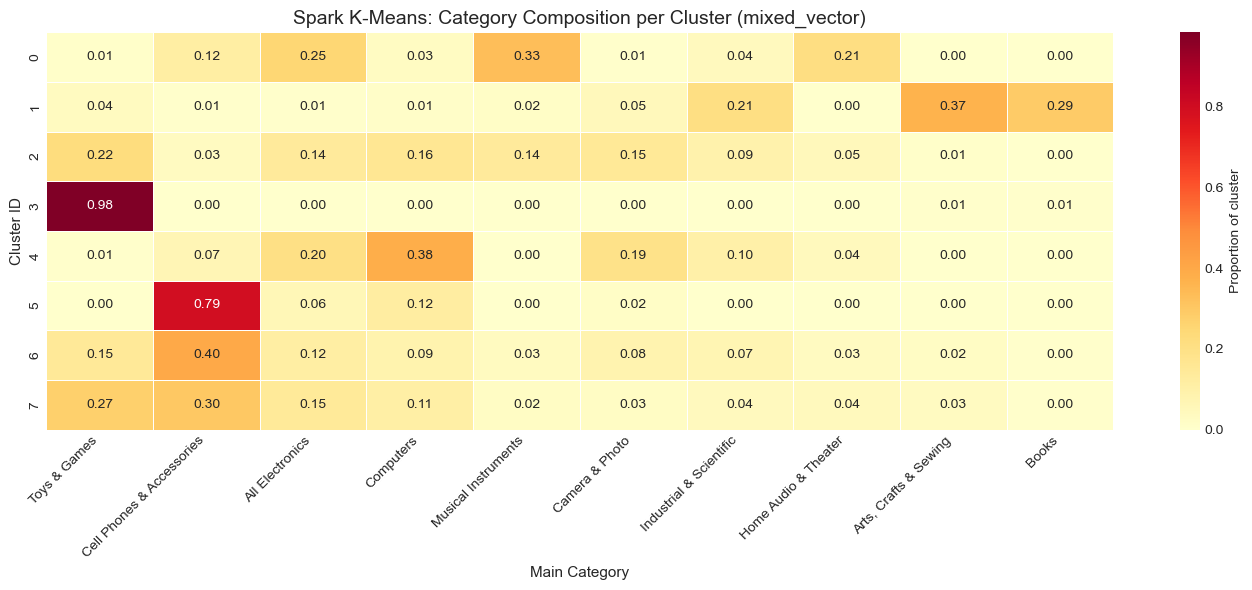

<Figure size 640x480 with 0 Axes>

In [22]:
# Plot 2 — Category composition heatmap
top_cats          = products_df['main_category'].value_counts().head(10).index.tolist()
cluster_cat_matrix= pd.crosstab(products_df['kmeans_cluster'], products_df['main_category'])[top_cats]
cluster_cat_norm  = cluster_cat_matrix.div(cluster_cat_matrix.sum(axis=1), axis=0)

plt.figure(figsize=(14, 6))
sns.heatmap(cluster_cat_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Proportion of cluster'})
plt.title('Spark K-Means: Category Composition per Cluster (mixed_vector)', fontsize=14)
plt.xlabel('Main Category', fontsize=11)
plt.ylabel('Cluster ID', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
plt.savefig('cluster_category_mixed_kmeans.png', dpi=150, bbox_inches='tight')



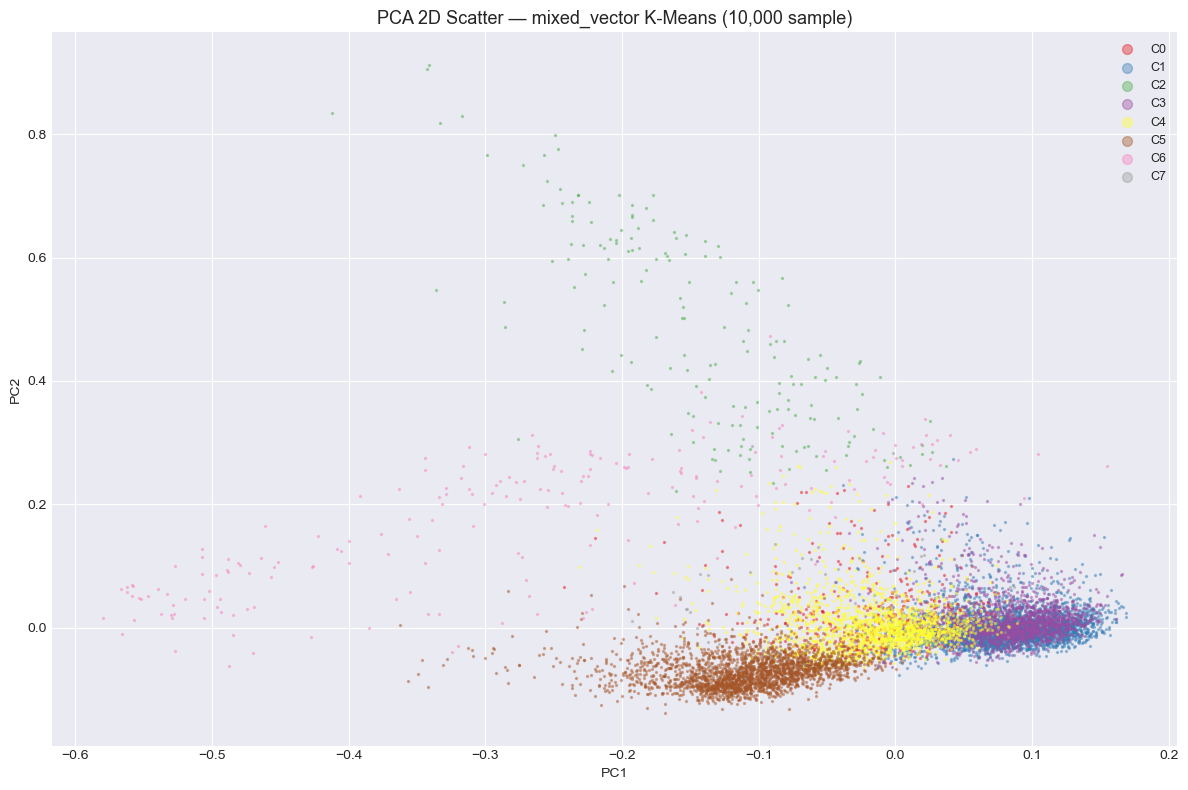

<Figure size 640x480 with 0 Axes>

In [24]:

#  fit and transform only on the small sample (to be fast)
X_plot = X_all[plot_idx].copy()  # extract sample first
pca_2d = PCA(n_components=2, random_state=RANDOM_SEED)
X_2d   = pca_2d.fit_transform(X_plot)  # only 10k × 50 

# Build lookup dict
asin_to_cluster = dict(zip(results_df['parent_asin'], results_df['kmeans_cluster']))
plot_labels     = np.array([asin_to_cluster.get(all_asins[i], -1) for i in plot_idx])

colors_2d = cm.Set1(np.linspace(0, 1, N_CLUSTERS))
fig, ax   = plt.subplots(figsize=(12, 8))
for cid in range(N_CLUSTERS):
    mask = plot_labels == cid
    if mask.sum() > 0:
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=[colors_2d[cid]], s=2, alpha=0.4, label=f'C{cid}')

ax.set_title(f'PCA 2D Scatter — mixed_vector K-Means ({sample_size_2d:,} sample)', fontsize=13)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend(markerscale=5, fontsize=9, loc='best')
plt.tight_layout()
plt.show()
plt.savefig('cluster_scatter_mixed_kmeans.png', dpi=150, bbox_inches='tight')


## 14. Export Results

Save full cluster assignments and profile sample to CSV for report

In [26]:
# Export full assignments (all 5.7M)
full_out = results_df[['parent_asin', 'kmeans_cluster', 'kmeans_cluster_name']].copy()
full_out.to_csv('product_mixed_kmeans_assignments_full.csv', index=False)
print(f'Saved: product_mixed_kmeans_assignments_full.csv  ({len(full_out):,} rows)')

# Export profile sample with metadata
profile_out = products_df[[
    'parent_asin', 'title', 'main_category', 'product_category',
    'price', 'average_rating', 'rating_number',
    'kmeans_cluster', 'kmeans_cluster_name'
]].copy()
profile_out.to_csv('product_mixed_kmeans_assignments_profile.csv', index=False)
print(f'Saved: product_mixed_kmeans_assignments_profile.csv  ({len(profile_out):,} rows)')

print()
print('─' * 55)
print('FINAL SUMMARY')
print('─' * 55)
print(f'Algorithm             : Spark K-Means')
print(f'Feature               : mixed_vector (Task 2 pipeline)')
print(f'Vector dimensions     : 387 → {PCA_COMPONENTS} (PCA)')
print(f'Total products        : {len(full_out):,}')
print(f'Clusters              : {N_CLUSTERS}')
print(f'Silhouette (cosine)   : {silhouette:.4f}')
print(f'WSSSE                 : {wssse:.4f}')
print(f'Batch size            : {BATCH_SIZE:,}')
print(f'PCA fit sample        : {PCA_SAMPLE_SIZE:,}')
print('─' * 55)

# Report-ready table
print()
print('─' * 65)
print('CLUSTER DISTRIBUTION ')
print('─' * 65)
print(f'{"Cluster Name":<45} {"Count":>10} {"Pct":>6}')
print('─' * 65)
total = len(results_df)
for cid, name in cluster_names.items():
    n   = (results_df['kmeans_cluster'] == cid).sum()
    pct = n / total * 100
    print(f'{name:<45} {n:>10,} {pct:>5.1f}%')
print('─' * 65)
print(f'{"TOTAL":<45} {total:>10,} {"100.0%":>6}')
print('─' * 65)

Saved: product_mixed_kmeans_assignments_full.csv  (5,737,625 rows)
Saved: product_mixed_kmeans_assignments_profile.csv  (22,790 rows)

───────────────────────────────────────────────────────
FINAL SUMMARY
───────────────────────────────────────────────────────
Algorithm             : Spark K-Means
Feature               : mixed_vector (Task 2 pipeline)
Vector dimensions     : 387 → 50 (PCA)
Total products        : 5,737,625
Clusters              : 8
Silhouette (cosine)   : 0.1766
WSSSE                 : 283969.4672
Batch size            : 10,000
PCA fit sample        : 50,000
───────────────────────────────────────────────────────

─────────────────────────────────────────────────────────────────
CLUSTER DISTRIBUTION 
─────────────────────────────────────────────────────────────────
Cluster Name                                       Count    Pct
─────────────────────────────────────────────────────────────────
Audio, Electronics & Instruments                 432,643   7.5%
Arts, Books &

## 15. Stop Spark Session

In [ ]:
spark.stop()
print('Spark session stopped.')